# Ćwiczenie F9 — Zurich: analiza danych
## Pomiar prędkości dźwięku w metalach metodą echa ultradźwiękowego

Notebook obliczeniowy do sprawozdania `zurich.tex`. Dane:

- `samples.csv` — próbki: grubość $l$ [mm] ($u_l = 0{,}05$ mm), masa $m$ [g] ($u_m = 0{,}01$ g);
- `diameters.csv` — średnice $d$ [mm] ($u_d = 0{,}05$ mm);
- `echo_times.csv` — czasy $t_n$ [µs] kolejnych impulsów na oscyloskopie ($u_t = 0{,}1$ µs).

**Konwencja niepewności.** Rozdzielczości przyrządów ($u_l$, $u_d$, $u_m$), niepewność odczytu czasu $u_t$
i niepewność współczynnika Poissona $u_\nu$ (połowa rozrzutu między gatunkami) traktowane są tak samo —
jako niepewności standardowe, bez dzielenia przez $\sqrt{3}$ (wariant zachowawczy). Dla $\nu$, które dominuje
niepewność $E$, podany jest też wariant z $u_\nu/\sqrt3$.

**Droga impulsu.** $t_1$ to impuls, który przeszedł przez próbkę raz (droga $l$); każde kolejne echo dokłada $2l$:
$s_n = (2n-1)\,l$. Czas na oscyloskopie liczony jest od wyzwolenia generatora i zawiera opóźnienie $\delta$
(głowice, warstwa oleju, docisk), które **może się różnić między próbkami**.

**Metoda.** Dla każdej próbki $i$ dopasowuje się
$$t_n = \tau_i\,(2n-1) + \delta_i,$$
gdzie $(2n-1)$ jest dokładne, a niepewność ma tylko $t_n$; $\tau_i = l_i/v_i$ — czas przejścia przez grubość próbki.
Stąd $v_i = l_i/\tau_i$, a niepewność $l_i$ wchodzi raz na próbkę (punkty jednej próbki dzielą ten sam błąd $l_i$):
$$\frac{u(v_i)}{v_i} = \sqrt{\left(\frac{u_\tau}{\tau}\right)^2 + \left(\frac{u_l}{l}\right)^2}.$$
Prędkość materiału — średnia ważona $v_i$, $w_i = 1/u^2(v_i)$, ze sprawdzeniem $\chi^2$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import locale

plt.rcParams.update({'figure.dpi': 150, 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3})
plt.rcParams['pdf.fonttype'] = 42
locale.setlocale(locale.LC_NUMERIC, 'pl_PL.UTF-8')
plt.rcParams['axes.formatter.use_locale'] = True

def pl(x, spec):
    '''Liczba z przecinkiem dziesiętnym — do legend i opisów na wykresach.'''
    return format(x, spec).replace('.', ',')

MATERIALY = ['brass', 'steel', 'aluminium']
NAZWA = {'brass': 'mosiądz', 'steel': 'stal', 'aluminium': 'aluminium'}

### Wartości tablicowe

Tabela 4.7.1 skryptu (20 °C): $\rho$, $E$, $v$. Niepewność wartości podanej jako jedna liczba — połowa ostatniej
cyfry ($u_\rho = 50$ kg/m³, $u_v = 5$ m/s); dla przedziałów (stal 5900–6000 m/s, $E$ aluminium 6,2–7,3·10¹⁰ Pa) —
środek i połowa szerokości.

Engineering ToolBox (dostęp 10.11.2026):
- *Poisson's Ratio*: aluminium 0,32–0,35, mosiądz 0,331–0,357, stal 0,265–0,305 → $\nu = 0{,}33;\ 0{,}34;\ 0{,}29$,
  $u_\nu = 0{,}02$;
- *Solids and Metals — Speed of Sound*: fala w ośrodku / w pręcie: Al walcowane 6420 / 5000, mosiądz 70/30 4700 / 3480,
  stal 1% C 5940 / 5180 m/s;
- *Metals and Alloys — Densities*: mosiądz 8400–8730, stopy Al 2770–2830, stal 7850 kg/m³.

In [2]:
TAB = pd.DataFrame({
    'rho':   [8.1e3, 7.8e3, 2.7e3],        # [kg/m^3]
    'u_rho': [50, 50, 50],
    'E':     [10.3e10, 21.5e10, 6.75e10],  # [Pa]
    'u_E':   [0.05e10, 0.05e10, 0.55e10],
    'v':     [3830, 5950, 6320],           # [m/s]
    'u_v':   [5, 50, 5],
    'nu':    [0.34, 0.29, 0.33],
    'u_nu':  [0.02, 0.02, 0.02],
    'v_lit': [4700, 5940, 6420],           # Engineering ToolBox, ośrodek
    'v_lit_rod': [3480, 5180, 5000],       # Engineering ToolBox, pręt
}, index=MATERIALY)
TAB

,rho,u_rho,E,u_E,v,u_v,nu,u_nu,v_lit,v_lit_rod
brass,8100.0,50,1.030000e+11,5.000000e+08,3830,5,0.34,0.02,4700,3480
steel,7800.0,50,2.150000e+11,5.000000e+08,5950,50,0.29,0.02,5940,5180
aluminium,2700.0,50,6.750000e+10,5.500000e+09,6320,5,0.33,0.02,6420,5000


### Dane

In [3]:
S = pd.read_csv('samples.csv').merge(pd.read_csv('diameters.csv'), on='sample')
T = pd.read_csv('echo_times.csv').merge(S[['sample', 'l', 'u_l']], on='sample')
T['k'] = 2 * T['n'] - 1                     # krotność grubości w drodze impulsu
T['s'] = T['k'] * T['l']                    # [mm]
T['u_s'] = T['k'] * T['u_l']
S

,sample,material,l,u_l,m,u_m,d,u_d
0,1,brass,9.55,0.05,22.86,0.01,18.90,0.05
1,2,brass,19.85,0.05,80.55,0.01,24.90,0.05
2,3,brass,24.70,0.05,101.16,0.01,24.90,0.05
3,4,brass,30.00,0.05,122.35,0.01,24.90,0.05
4,5,steel,10.00,0.05,24.37,0.01,19.75,0.05
5,6,steel,19.00,0.05,72.35,0.01,24.95,0.05
6,7,steel,25.20,0.05,90.04,0.01,24.15,0.05
7,8,steel,30.20,0.05,114.95,0.01,24.90,0.05
8,9,aluminium,9.20,0.05,8.17,0.01,20.00,0.05
9,10,aluminium,19.00,0.05,26.41,0.01,25.15,0.05


### Tabela surowych pomiarów (do sekcji Wyniki)

In [4]:
szer = T.pivot(index='sample', columns='n', values='t')
for _, r in S.iterrows():
    ts = ' & '.join('{--}' if np.isnan(szer.loc[r['sample'], n]) else f"{szer.loc[r['sample'], n]:.2f}" for n in range(1, 6))
    print(f"{r['sample']} & {NAZWA[r['material']]} & {r['l']:.2f} & {r['d']:.2f} & {r['m']:.2f} & {ts} \\\\")

1 & mosiądz & 9.55 & 18.90 & 22.86 & 3.44 & 7.76 & 12.07 & 16.39 & 20.93 \\
2 & mosiądz & 19.85 & 24.90 & 80.55 & 5.68 & 14.53 & 23.70 & 32.55 & 41.45 \\
3 & mosiądz & 24.70 & 24.90 & 101.16 & 6.78 & 17.80 & 29.11 & 40.12 & 51.18 \\
4 & mosiądz & 30.00 & 24.90 & 122.35 & 7.94 & 21.76 & 35.38 & 48.76 & 61.93 \\
5 & stal & 10.00 & 19.75 & 24.37 & 2.90 & 6.30 & 9.70 & 13.10 & 16.48 \\
6 & stal & 19.00 & 24.95 & 72.35 & 4.20 & 10.68 & 17.05 & 23.42 & 29.69 \\
7 & stal & 25.20 & 24.15 & 90.04 & 5.50 & 13.97 & 22.36 & 31.02 & {--} \\
8 & stal & 30.20 & 24.90 & 114.95 & 6.20 & 16.48 & 26.54 & 36.86 & {--} \\
9 & aluminium & 9.20 & 20.00 & 8.17 & 2.65 & 5.52 & 8.36 & 11.21 & 14.06 \\
10 & aluminium & 19.00 & 25.15 & 26.41 & 4.20 & 10.09 & 16.00 & {--} & {--} \\
11 & aluminium & 24.80 & 24.85 & 33.65 & 5.10 & 12.79 & 20.71 & 28.33 & 36.32 \\
12 & aluminium & 29.90 & 24.90 & 40.58 & 5.90 & 15.20 & 24.27 & 33.86 & {--} \\


### Wykresy surowe $s(t)$ (do sekcji Wyniki)

Słupki błędów $u(s) = (2n-1)\,u_l \le 0{,}45$ mm i $u_t = 0{,}1$ µs są mniejsze od znaczników.

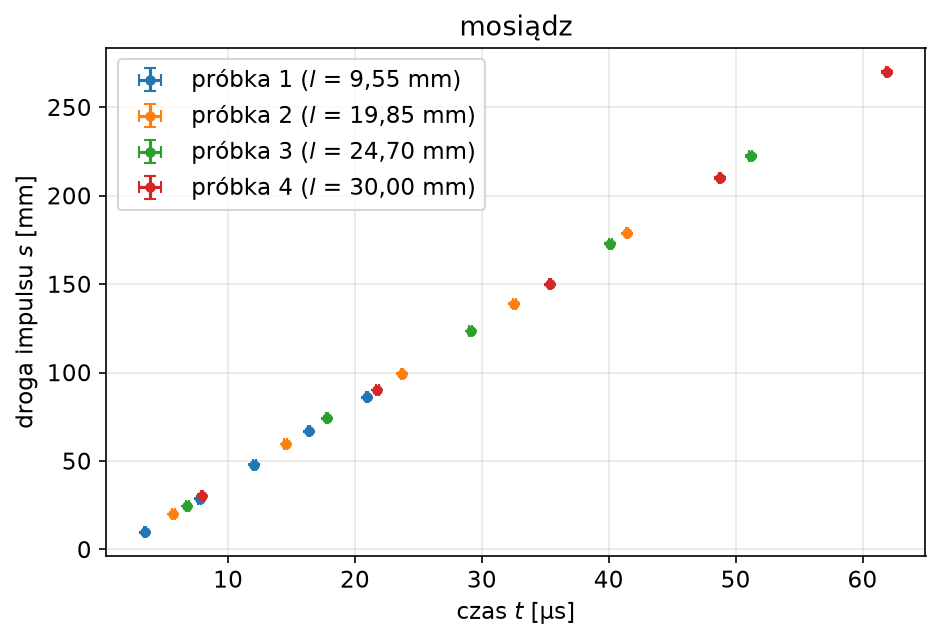

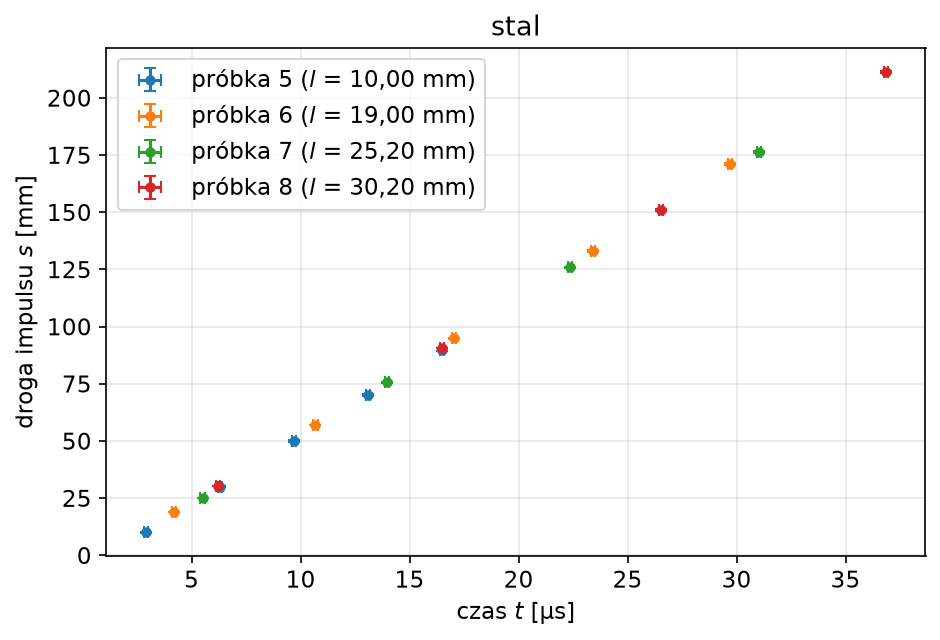

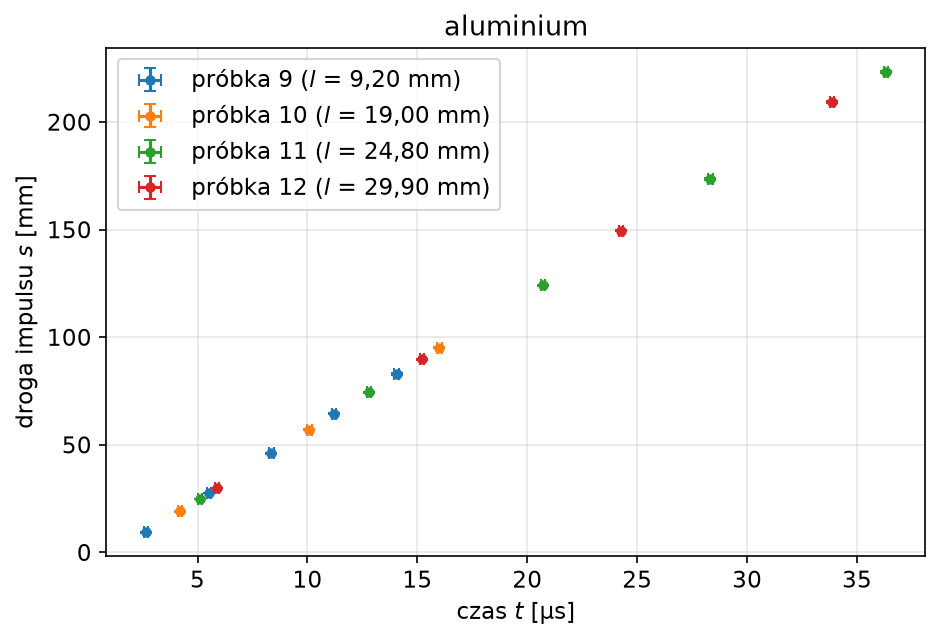

In [5]:
def wykres_surowy(mat, ax):
    for k, g in T[T['material'] == mat].groupby('sample'):
        l = g['l'].iloc[0]
        ax.errorbar(g['t'], g['s'], xerr=g['u_t'], yerr=g['u_s'], fmt='o', ms=4, capsize=3,
                    label=f'próbka {k} ($l$ = {pl(l, ".2f")} mm)')
    ax.set_xlabel('czas $t$ [µs]')
    ax.set_ylabel('droga impulsu $s$ [mm]')
    ax.legend()

for mat in MATERIALY:
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    wykres_surowy(mat, ax)
    ax.set_title(NAZWA[mat])
    fig.tight_layout()
    fig.savefig(f'{mat}_raw.pdf')
    plt.show()

### Dopasowanie $t_n = \tau_i(2n-1) + \delta_i$ dla każdej próbki

Ważona regresja liniowa, wagi $w_n = 1/u_t^2$, macierz kowariancji $C = (A^T W A)^{-1}$ (odpowiednik
`curve_fit(..., sigma=u_t, absolute_sigma=True)`); $u_\tau = \sqrt{C_{11}}$, $u_\delta = \sqrt{C_{22}}$.
Gdy $\chi^2/\nu > 1$ (próbki 4 i 12), niepewności parametrów mnoży się przez $\sqrt{\chi^2/\nu}$, żeby
rozrzut punktów tej próbki był odzwierciedlony w jej wadze w średniej.

In [6]:
def dopasuj_probke(g):
    A = np.vstack([g['k'], np.ones(len(g))]).T
    W = np.diag(1 / g['u_t']**2)
    Cov = np.linalg.inv(A.T @ W @ A)
    tau, delta = Cov @ A.T @ W @ g['t']
    r = g['t'] - A @ np.array([tau, delta])
    chi2, nu = np.sum((r / g['u_t'])**2), len(g) - 2
    skala = max(1.0, np.sqrt(chi2 / nu)) if nu > 0 else 1.0
    Cov = Cov * skala**2
    l, u_l = g['l'].iloc[0], g['u_l'].iloc[0]
    v = l / tau * 1e3                                   # mm/µs → m/s
    u_v_fit = v * np.sqrt(Cov[0, 0]) / tau
    u_v_l = v * u_l / l
    return dict(material=g['material'].iloc[0], l=l, tau=tau, u_tau=np.sqrt(Cov[0, 0]),
                delta=delta, u_delta=np.sqrt(Cov[1, 1]), v=v, u_v_fit=u_v_fit, u_v_l=u_v_l,
                u_v=np.hypot(u_v_fit, u_v_l), chi2=chi2, nu=nu, skala=skala, ss=np.sum(r**2))

P = pd.DataFrame({k: dopasuj_probke(g) for k, g in T.groupby('sample')}).T
for c in P.columns.drop('material'):
    P[c] = P[c].astype(float)
for k, r in P.iterrows():
    print(f"{k:2d} {NAZWA[r.material]:9s}  τ = {r.tau:.4f} ± {r.u_tau:.4f} µs   δ = {r.delta:.3f} ± {r.u_delta:.3f} µs   "
          f"v = ({r.v:.0f} ± {r.u_v:.0f}) m/s [fit {r.u_v_fit:.0f}, l {r.u_v_l:.0f}]   χ² = {r.chi2:.2f}/{r.nu:.0f}   skala {r.skala:.2f}")

dof = P['nu'].sum()
print(f"\nRozrzut residuów wewnątrz próbek (wszystkie próbki razem): {np.sqrt(P['ss'].sum() / dof) * 1e3:.0f} ns, ν = {dof:.0f}")
print(f"Suma χ² = {P['chi2'].sum():.1f} / {dof:.0f}")

print('\n% LaTeX (próbki):')
for k, r in P.iterrows():
    print(f"{k} & {NAZWA[r.material]} & {r.v:.0f} & {r.u_v:.0f} & {r.delta:.2f} & {r.u_delta:.2f} & {r.chi2:.2f}/{r.nu:.0f} \\\\")

 1 mosiądz    τ = 2.1805 ± 0.0158 µs   δ = 1.216 ± 0.091 µs   v = (4380 ± 39) m/s [fit 32, l 23]   χ² = 2.03/3   skala 1.00
 2 mosiądz    τ = 4.4780 ± 0.0158 µs   δ = 1.192 ± 0.091 µs   v = (4433 ± 19) m/s [fit 16, l 11]   χ² = 2.53/3   skala 1.00
 3 mosiądz    τ = 5.5560 ± 0.0158 µs   δ = 1.218 ± 0.091 µs   v = (4446 ± 16) m/s [fit 13, l 9]   χ² = 2.18/3   skala 1.00
 4 mosiądz    τ = 6.7490 ± 0.0376 µs   δ = 1.409 ± 0.216 µs   v = (4445 ± 26) m/s [fit 25, l 7]   χ² = 16.95/3   skala 2.38
 5 stal       τ = 1.6980 ± 0.0158 µs   δ = 1.206 ± 0.091 µs   v = (5889 ± 62) m/s [fit 55, l 29]   χ² = 0.02/3   skala 1.00
 6 stal       τ = 3.1860 ± 0.0158 µs   δ = 1.078 ± 0.091 µs   v = (5964 ± 33) m/s [fit 30, l 16]   χ² = 1.32/3   skala 1.00
 7 stal       τ = 4.2475 ± 0.0224 µs   δ = 1.222 ± 0.102 µs   v = (5933 ± 33) m/s [fit 31, l 12]   χ² = 1.52/2   skala 1.00
 8 stal       τ = 5.1020 ± 0.0224 µs   δ = 1.112 ± 0.102 µs   v = (5919 ± 28) m/s [fit 26, l 10]   χ² = 1.19/2   skala 1.00
 9 alumin

### Prędkość materiału — średnia ważona po próbkach

$\bar v = \dfrac{\sum v_i/u_i^2}{\sum 1/u_i^2}$, $u(\bar v) = \left(\sum 1/u_i^2\right)^{-1/2}$, test $\chi^2 = \sum (v_i - \bar v)^2/u_i^2$
przy $\nu = 3$.

In [7]:
def srednia_wazona(x, u):
    w = 1 / u**2
    return np.sum(w * x) / np.sum(w), np.sum(w)**-0.5

WYN = pd.DataFrame(index=MATERIALY, columns=['v', 'u_v', 'chi2'], dtype=float)
for mat in MATERIALY:
    g = P[P['material'] == mat]
    v, u = srednia_wazona(g['v'], g['u_v'])
    WYN.loc[mat] = [v, u, np.sum(((g['v'] - v) / g['u_v'])**2)]
    rest = g.iloc[1:]
    vr, _ = srednia_wazona(rest['v'], rest['u_v'])
    z = lambda x, ux, y, uy: abs(x - y) / np.sqrt(ux**2 + uy**2)
    print(f"{NAZWA[mat]:9s}  v = ({v:.0f} ± {u:.0f}) m/s   χ² = {WYN.loc[mat, 'chi2']:.2f}/3   "
          f"najcieńsza próbka: {g['v'].iloc[0]:.0f} ± {g['u_v'].iloc[0]:.0f} vs pozostałe {vr:.0f} ± {_:.0f} ({100 * (g['v'].iloc[0] / vr - 1):+.1f}%, "
          f"{z(g['v'].iloc[0], g['u_v'].iloc[0], vr, _):.1f}σ)   waga najcieńszej: {100 * g['u_v'].iloc[0]**-2 / np.sum(g['u_v']**-2):.1f}%")

mosiądz    v = (4437 ± 11) m/s   χ² = 2.59/3   najcieńsza próbka: 4380 ± 39 vs pozostałe 4441 ± 11 (-1.4%, 1.5σ)   waga najcieńszej: 7.2%
stal       v = (5932 ± 17) m/s   χ² = 1.57/3   najcieńsza próbka: 5889 ± 62 vs pozostałe 5936 ± 18 (-0.8%, 0.7σ)   waga najcieńszej: 7.7%
aluminium  v = (6390 ± 23) m/s   χ² = 2.86/3   najcieńsza próbka: 6454 ± 80 vs pozostałe 6385 ± 24 (+1.1%, 0.8σ)   waga najcieńszej: 8.2%


### Sprawdzenie przypisania drogi

Gdyby $t_1$ było pierwszym echem ($s_n = 2nl$), wspólna prosta $s = at + b$ dla próbek jednego materiału
nie mogłaby pasować — punkty każdej próbki przesuwają się o inne $l$. Dla porównania $\chi^2$ obu przypisań
(wspólna prosta, wariancja efektywna).

In [8]:
def chi2_wspolna(g, s):
    u_s = s / g['l'] * g['u_l']
    a, b = 5.0, -6.0
    for _ in range(50):
        sig = np.sqrt(u_s**2 + (a * g['u_t'])**2)
        a, b = np.polyfit(g['t'], s, 1, w=1 / sig)
    sig = np.sqrt(u_s**2 + (a * g['u_t'])**2)
    return np.sum(((s - a * g['t'] - b) / sig)**2), len(g) - 2

for mat in MATERIALY:
    g = T[T['material'] == mat]
    c1, n1 = chi2_wspolna(g, (2 * g['n'] - 1) * g['l'])
    c2, n2 = chi2_wspolna(g, 2 * g['n'] * g['l'])
    print(f"{NAZWA[mat]:9s}  s = (2n-1)l: χ² = {c1:.0f}/{n1}    s = 2nl: χ² = {c2:.0f}/{n2}")

mosiądz    s = (2n-1)l: χ² = 29/18    s = 2nl: χ² = 2970/18
stal       s = (2n-1)l: χ² = 20/16    s = 2nl: χ² = 1843/16
aluminium  s = (2n-1)l: χ² = 14/15    s = 2nl: χ² = 1528/15


### Wykresy z dopasowaniem (do sekcji Opracowanie)

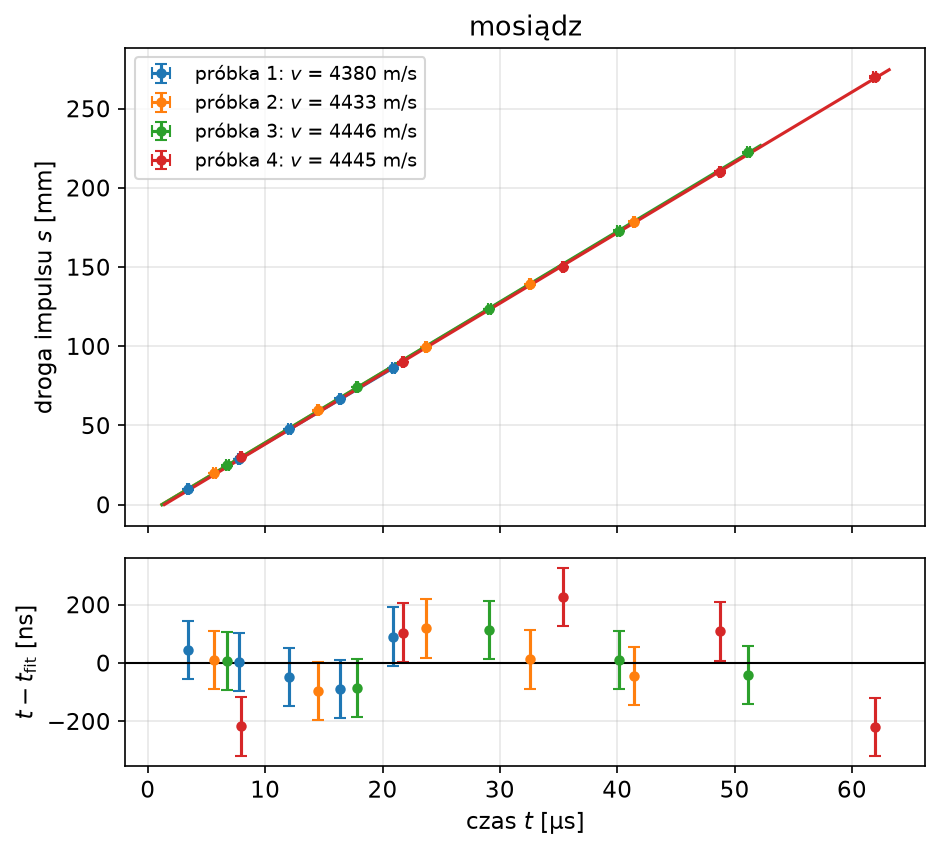

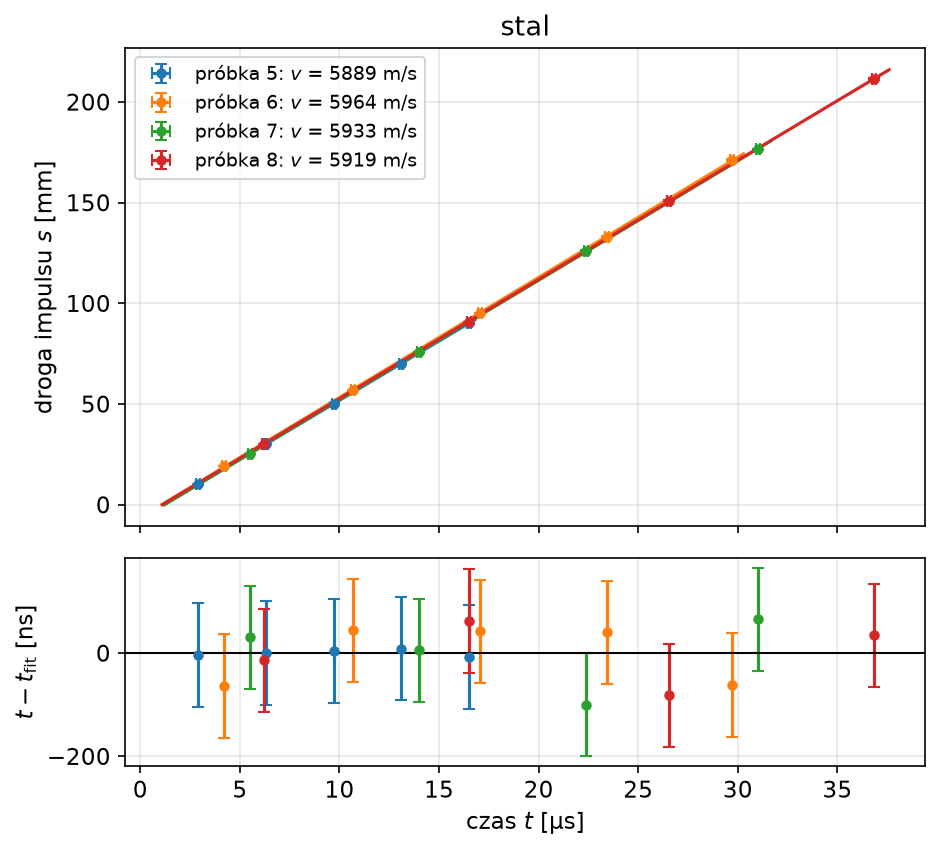

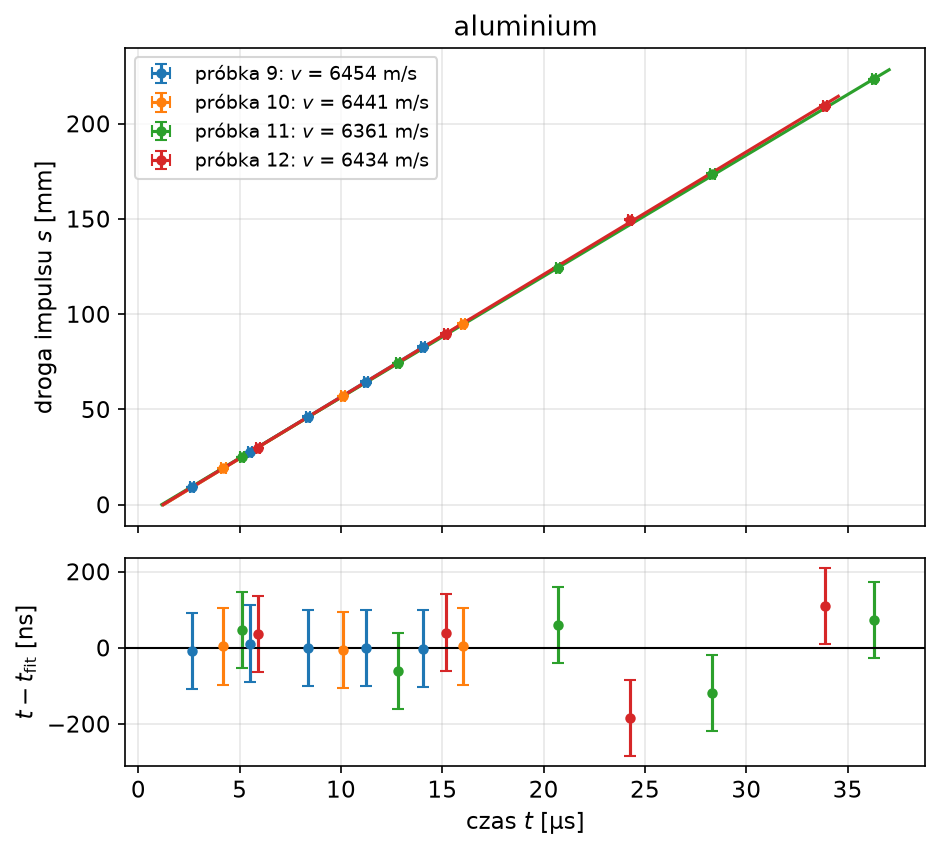

In [9]:
for mat in MATERIALY:
    g = T[T['material'] == mat]
    fig, (ax, axr) = plt.subplots(2, 1, figsize=(6.4, 5.8), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
    for k, h in g.groupby('sample'):
        r = P.loc[k]
        e = ax.errorbar(h['t'], h['s'], xerr=h['u_t'], yerr=h['u_s'], fmt='o', ms=4, capsize=3,
                        label=f'próbka {k}: $v$ = {r.v:.0f} m/s')
        tt = np.linspace(r.delta, h['t'].max() * 1.02, 50)
        ax.plot(tt, (tt - r.delta) / r.tau * r.l, '-', lw=1.5, color=e[0].get_color())
        res = h['t'] - (r.tau * h['k'] + r.delta)
        axr.errorbar(h['t'], res * 1e3, yerr=h['u_t'] * 1e3, fmt='o', ms=4, capsize=3, color=e[0].get_color())
    ax.set_ylabel('droga impulsu $s$ [mm]')
    ax.set_title(NAZWA[mat])
    ax.legend(fontsize=9)
    axr.axhline(0, color='k', lw=1)
    axr.set_xlabel('czas $t$ [µs]')
    axr.set_ylabel('$t - t_\\mathrm{fit}$ [ns]')
    fig.tight_layout()
    fig.savefig(f'{mat}.pdf')
    plt.show()

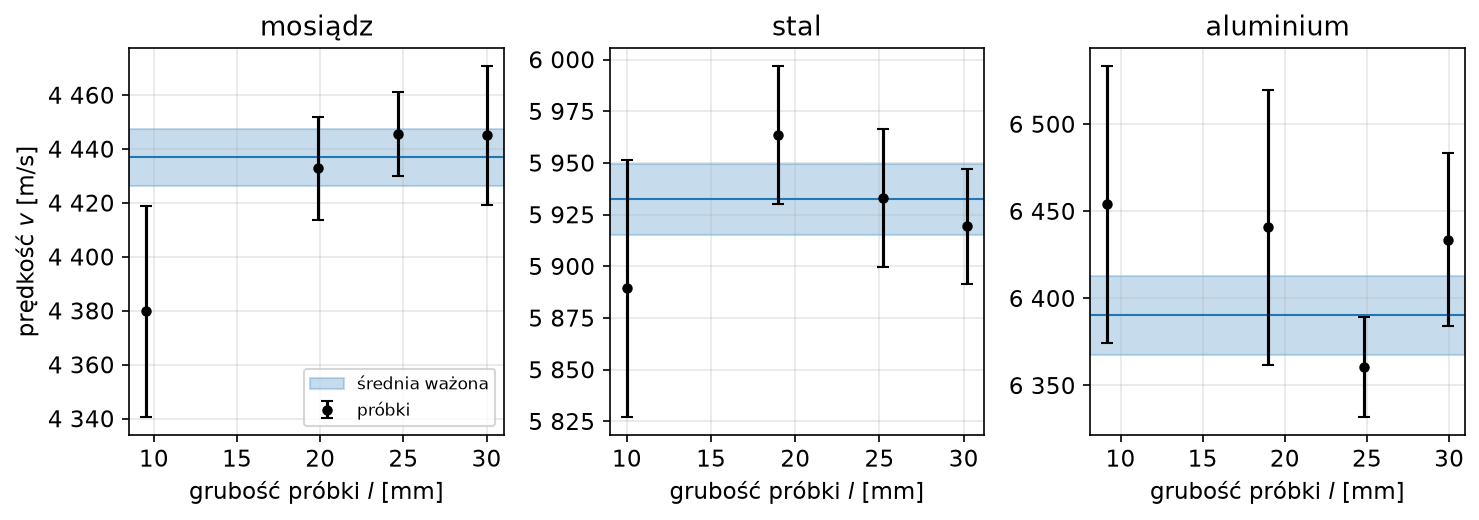

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, mat in zip(axs, MATERIALY):
    g = P[P['material'] == mat]
    v, u = WYN.loc[mat, 'v'], WYN.loc[mat, 'u_v']
    ax.axhspan(v - u, v + u, color='tab:blue', alpha=0.25, label='średnia ważona')
    ax.axhline(v, color='tab:blue', lw=1)
    ax.errorbar(g['l'], g['v'], yerr=g['u_v'], fmt='o', ms=4, capsize=3, color='k', label='próbki')
    ax.set_title(NAZWA[mat])
    ax.set_xlabel('grubość próbki $l$ [mm]')
axs[0].set_ylabel('prędkość $v$ [m/s]')
axs[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig('velocities.pdf')
plt.show()

### Porównanie z teorią

Pręt (4.7.8): $v = \sqrt{E/\rho}$; ośrodek (4.7.13): $v = \sqrt{E f(\nu)/\rho}$, $f(\nu) = \dfrac{1-\nu}{(1+\nu)(1-2\nu)}$.
$\dfrac{u(v)}{v} = \dfrac12\sqrt{(u_E/E)^2 + (u_\rho/\rho)^2 + (f'/f\,u_\nu)^2}$. Test: $|v_1 - v_2|/\sqrt{u^2(v_1) + u^2(v_2)}$
(z niezaokrąglonych wartości).

In [11]:
def f_nu(nu):
    return (1 - nu) / ((1 + nu) * (1 - 2 * nu))

def dlnf_dnu(nu):
    return -1 / (1 - nu) - 1 / (1 + nu) + 2 / (1 - 2 * nu)

z = lambda x, ux, y, uy: abs(x - y) / np.sqrt(ux**2 + uy**2)

TEOR = pd.DataFrame(index=MATERIALY)
rel_rod = 0.5 * np.sqrt((TAB['u_E'] / TAB['E'])**2 + (TAB['u_rho'] / TAB['rho'])**2)
TEOR['v_rod'] = np.sqrt(TAB['E'] / TAB['rho'])
TEOR['u_v_rod'] = TEOR['v_rod'] * rel_rod
TEOR['v_bulk'] = TEOR['v_rod'] * np.sqrt(f_nu(TAB['nu']))
TEOR['u_v_bulk'] = TEOR['v_bulk'] * np.sqrt(rel_rod**2 + (0.5 * dlnf_dnu(TAB['nu']) * TAB['u_nu'])**2)
for mat in MATERIALY:
    r, w, t = TEOR.loc[mat], WYN.loc[mat], TAB.loc[mat]
    print(f"{NAZWA[mat]:9s}  v = ({w.v:.0f} ± {w.u_v:.0f})   "
          f"pręt: {r.v_rod:.0f} ± {r.u_v_rod:.0f} [{z(w.v, w.u_v, r.v_rod, r.u_v_rod):.1f}]   "
          f"ośrodek: {r.v_bulk:.0f} ± {r.u_v_bulk:.0f} [{z(w.v, w.u_v, r.v_bulk, r.u_v_bulk):.1f}]   "
          f"skrypt: {t.v:.0f} ± {t.u_v:.0f} [{z(w.v, w.u_v, t.v, t.u_v):.1f}]   "
          f"lit.: {t.v_lit} [{z(w.v, w.u_v, t.v_lit, 5):.1f}, {100 * (w.v / t.v_lit - 1):+.1f}%] / {t.v_lit_rod}")
print('\nSpójność tabeli skryptu: v_skrypt vs prędkości z jej własnych E, ρ:')
for mat in MATERIALY:
    r, t = TEOR.loc[mat], TAB.loc[mat]
    print(f"{NAZWA[mat]:9s}  skrypt {t.v:.0f}   pręt {r.v_rod:.0f} ({100 * (t.v / r.v_rod - 1):+.0f}%)   "
          f"ośrodek {r.v_bulk:.0f} ± {r.u_v_bulk:.0f} ({100 * (t.v / r.v_bulk - 1):+.0f}%, {z(t.v, t.u_v, r.v_bulk, r.u_v_bulk):.1f}σ)")

mosiądz    v = (4437 ± 11)   pręt: 3566 ± 14 [49.7]   ośrodek: 4424 ± 177 [0.1]   skrypt: 3830 ± 5 [52.0]   lit.: 4700.0 [22.6, -5.6%] / 3480.0
stal       v = (5932 ± 17)   pręt: 5250 ± 18 [27.4]   ośrodek: 6010 ± 156 [0.5]   skrypt: 5950 ± 50 [0.3]   lit.: 5940.0 [0.4, -0.1%] / 5180.0
aluminium  v = (6390 ± 23)   pręt: 5000 ± 209 [6.6]   ośrodek: 6086 ± 337 [0.9]   skrypt: 6320 ± 5 [3.0]   lit.: 6420.0 [1.3, -0.5%] / 5000.0

Spójność tabeli skryptu: v_skrypt vs prędkości z jej własnych E, ρ:
mosiądz    skrypt 3830   pręt 3566 (+7%)   ośrodek 4424 ± 177 (-13%, 3.3σ)
stal       skrypt 5950   pręt 5250 (+13%)   ośrodek 6010 ± 156 (-1%, 0.4σ)
aluminium  skrypt 6320   pręt 5000 (+26%)   ośrodek 6086 ± 337 (+4%, 0.7σ)


### Gęstość

$\rho = \dfrac{4m}{\pi d^2 l}$,
$\dfrac{u(\rho)}{\rho} = \sqrt{\left(\dfrac{u_m}{m}\right)^2 + \left(\dfrac{2u_d}{d}\right)^2 + \left(\dfrac{u_l}{l}\right)^2}$.
Dla materiału — średnia arytmetyczna z $u = s/\sqrt{n}$ (średnia ważona ma $\chi^2/\nu > 1$ przez najcieńsze próbki).

In [12]:
S['rho'] = 4 * S['m'] / (np.pi * S['d']**2 * S['l']) * 1e6          # g/mm³ → kg/m³
S['u_rho'] = S['rho'] * np.sqrt((S['u_m'] / S['m'])**2 + (2 * S['u_d'] / S['d'])**2 + (S['u_l'] / S['l'])**2)
RHO = pd.DataFrame(index=MATERIALY, columns=['rho', 'u_rho'], dtype=float)
for mat in MATERIALY:
    g = S[S['material'] == mat]
    sr, u_sr = g['rho'].mean(), g['rho'].std(ddof=1) / np.sqrt(len(g))
    RHO.loc[mat] = [sr, u_sr]
    xw, uw = srednia_wazona(g['rho'], g['u_rho'])
    chi2 = np.sum(((g['rho'] - xw) / g['u_rho'])**2)
    rest = g.iloc[1:]['rho'].mean()
    print(f"{NAZWA[mat]:9s}  ρ = ({sr:.0f} ± {u_sr:.0f}) kg/m³   [ważona: {xw:.0f} ± {uw:.0f}, χ² = {chi2:.1f}/3]   "
          f"ρ_tab = {TAB.loc[mat, 'rho']:.0f}  test {z(sr, u_sr, TAB.loc[mat, 'rho'], TAB.loc[mat, 'u_rho']):.1f}  "
          f"({100 * (sr / TAB.loc[mat, 'rho'] - 1):+.1f}%)   najcieńsza vs reszta: {100 * (g['rho'].iloc[0] / rest - 1):+.1f}%")
print('% LaTeX:')
for _, r in S.iterrows():
    print(f"{r['sample']} & {NAZWA[r['material']]} & {r['rho']:.0f} & {r['u_rho']:.0f} \\\\")

mosiądz    ρ = (8413 ± 43) kg/m³   [ważona: 8391 ± 21, χ² = 7.5/3]   ρ_tab = 8100  test 4.8  (+3.9%)   najcieńsza vs reszta: +1.9%
stal       ρ = (7840 ± 39) kg/m³   [ważona: 7820 ± 19, χ² = 6.7/3]   ρ_tab = 7800  test 0.6  (+0.5%)   najcieńsza vs reszta: +2.0%
aluminium  ρ = (2802 ± 9) kg/m³   [ważona: 2797 ± 7, χ² = 2.6/3]   ρ_tab = 2700  test 2.0  (+3.8%)   najcieńsza vs reszta: +1.2%
% LaTeX:
1 & mosiądz & 8532 & 64 \\
2 & mosiądz & 8333 & 40 \\
3 & mosiądz & 8411 & 38 \\
4 & mosiądz & 8375 & 36 \\
5 & stal & 7955 & 57 \\
6 & stal & 7789 & 37 \\
7 & stal & 7800 & 36 \\
8 & stal & 7817 & 34 \\
9 & aluminium & 2827 & 21 \\
10 & aluminium & 2798 & 13 \\
11 & aluminium & 2798 & 13 \\
12 & aluminium & 2787 & 12 \\


### Moduł podłużny i moduł Younga

Pomiar daje bezpośrednio **moduł podłużny** $M = \rho v^2$ (moduł fali w ośrodku nieograniczonym). Moduł Younga
wymaga $\nu$: $E = M/f(\nu) = \rho v^2 \dfrac{(1+\nu)(1-2\nu)}{1-\nu}$.

$\dfrac{u(M)}{M} = \sqrt{\left(\dfrac{u_\rho}{\rho}\right)^2 + \left(\dfrac{2u_v}{v}\right)^2}$,
$\dfrac{u(E)}{E} = \sqrt{\left(\dfrac{u(M)}{M}\right)^2 + \left(\dfrac{f'}{f}u_\nu\right)^2}$.

In [13]:
MOD = pd.DataFrame(index=MATERIALY)
rho, u_rho = RHO['rho'], RHO['u_rho']
v, u_v = WYN['v'], WYN['u_v']
MOD['M'] = rho * v**2
MOD['u_M'] = MOD['M'] * np.sqrt((u_rho / rho)**2 + (2 * u_v / v)**2)
MOD['E'] = MOD['M'] / f_nu(TAB['nu'])
rel_nu = dlnf_dnu(TAB['nu']) * TAB['u_nu']
MOD['u_E'] = MOD['E'] * np.sqrt((MOD['u_M'] / MOD['M'])**2 + rel_nu**2)
MOD['u_E_sqrt3'] = MOD['E'] * np.sqrt((MOD['u_M'] / MOD['M'])**2 + (rel_nu / np.sqrt(3))**2)
for mat, r in MOD.iterrows():
    t = TAB.loc[mat]
    udz = (rel_nu[mat]**2) / ((r.u_E / r.E)**2)
    print(f"{NAZWA[mat]:9s}  M = ({r.M / 1e10:.2f} ± {r.u_M / 1e10:.2f})·10¹⁰ Pa   M/E = {f_nu(t.nu):.2f}   "
          f"E = ({r.E / 1e10:.2f} ± {r.u_E / 1e10:.2f})·10¹⁰ Pa [z u_ν/√3: ± {r.u_E_sqrt3 / 1e10:.2f}]   "
          f"E_tab = {t.E / 1e10:.2f} ± {t.u_E / 1e10:.2f}   test {z(r.E, r.u_E, t.E, t.u_E):.1f} "
          f"[√3: {z(r.E, r.u_E_sqrt3, t.E, t.u_E):.1f}]   udział ν w u²(E): {100 * udz:.1f}%")

mosiądz    M = (16.56 ± 0.12)·10¹⁰ Pa   M/E = 1.54   E = (10.76 ± 0.86)·10¹⁰ Pa [z u_ν/√3: ± 0.50]   E_tab = 10.30 ± 0.05   test 0.5 [√3: 0.9]   udział ν w u²(E): 99.2%
stal       M = (27.59 ± 0.21)·10¹⁰ Pa   M/E = 1.31   E = (21.06 ± 1.10)·10¹⁰ Pa [z u_ν/√3: ± 0.65]   E_tab = 21.50 ± 0.05   test 0.4 [√3: 0.7]   udział ν w u²(E): 97.9%
aluminium  M = (11.44 ± 0.09)·10¹⁰ Pa   M/E = 1.48   E = (7.72 ± 0.57)·10¹⁰ Pa [z u_ν/√3: ± 0.33]   E_tab = 6.75 ± 0.55   test 1.2 [√3: 1.5]   udział ν w u²(E): 98.9%


### Rysunek do wstępu: element pręta

Odtworzenie Rys. 4.7.1 skryptu (naprężenia na element pręta) jako czysty wektor.

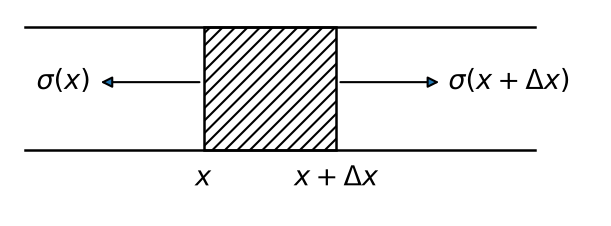

In [14]:
fig, ax = plt.subplots(figsize=(5.0, 1.7))
ax.plot([0, 10], [0, 0], 'k', lw=1.2)
ax.plot([0, 10], [2, 2], 'k', lw=1.2)
ax.add_patch(plt.Rectangle((3.5, 0), 2.6, 2, facecolor='none', edgecolor='k', hatch='////', lw=1.2))
ax.annotate('', xy=(1.4, 1.1), xytext=(3.5, 1.1), arrowprops=dict(arrowstyle='-|>', lw=1))
ax.annotate('', xy=(8.2, 1.1), xytext=(6.1, 1.1), arrowprops=dict(arrowstyle='-|>', lw=1))
ax.text(1.3, 1.1, r'$\sigma(x)$', ha='right', va='center', fontsize=13)
ax.text(8.3, 1.1, r'$\sigma(x+\Delta x)$', ha='left', va='center', fontsize=13)
ax.text(3.5, -0.25, r'$x$', ha='center', va='top', fontsize=13)
ax.text(6.1, -0.25, r'$x+\Delta x$', ha='center', va='top', fontsize=13)
ax.set_xlim(-0.2, 11.2); ax.set_ylim(-1.0, 2.2)
ax.axis('off')
fig.savefig('rod_element.pdf', bbox_inches='tight')
plt.show()